In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2
from fwh_analysis import FWHDataset, FWHPlotter


def fft(dataset, col='P_obs', title="FFT Spectrum", max_freq=None, auto_scale=True):
    if type(dataset) == pd.DataFrame:
        time = dataset['Time'].values
        pressure = dataset[col].values
    elif type(dataset) == FWHDataset:
        time = dataset.data['Time'].values
        pressure = dataset.data[col].values
    
    dt = time[1] - time[0]
    N = len(time)
    
    freqs = np.fft.rfftfreq(N, d=dt)
    fft_complex = np.fft.rfft(pressure)
    
    amplitude = 2.0 / N * np.abs(fft_complex)
    amplitude[0] = amplitude[0] / 2
    phases = np.angle(fft_complex)
    
    if auto_scale and max_freq is None:
        max_amp = np.max(amplitude)
        threshold = max(0.01 * max_amp, 1e-3) 
        
        significant_indices = np.where(amplitude > threshold)[0]
        
        if len(significant_indices) > 0:
            highest_significant_freq = freqs[significant_indices[-1]]
            max_freq = min(highest_significant_freq * 1.15, freqs[-1])
        else:
            max_freq = freqs[-1]  # Fallback if flatline

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(freqs, amplitude, linestyle='-', color='b', markersize=4)
    
    ax.set_title(title, weight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (Pa)')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if max_freq:
        ax.set_xlim(left=0, right=max_freq)
        
    plt.tight_layout()
    plt.show()
    
    return freqs, amplitude, phases

def dft(t, p, f_1bpf, num_harmonics=10):
    if type(t) == pd.core.series.Series:
        T_period = t.iloc[-1] - t.iloc[0]
    elif type(t) == list:
        T_period = t[-1] - t[0]
    freqs = np.zeros(num_harmonics)
    amps = np.zeros(num_harmonics)
    phases = np.zeros(num_harmonics)

    for n in range(1, num_harmonics + 1):
        freqs[n-1] = n * f_1bpf
        omega_n = 2 * np.pi * freqs[n-1]

        real = np.trapezoid(p * np.cos(omega_n * t), t) * (2.0 / T_period)
        imag = np.trapezoid(p * np.sin(omega_n * t), t) * (2.0 / T_period)

        amps[n-1] = np.sqrt(real ** 2 + imag **2)
        phases[n-1] = np.arctan2(-imag, real)

    return freqs, amps, phases

def dft_spatial(theta_rad, p_theta, num_modes):
    theta_full = np.append(theta_rad, 2 * np.pi)
    p_full = np.append(p_theta, p_theta[0])
    
    modes = np.arange(1, num_modes + 1)
    amps = np.zeros(num_modes)
    phases = np.zeros(num_modes)

    for i, m, in enumerate(modes):
        real = np.trapezoid(p_full * np.cos(m * theta_full), theta_full) / np.pi
        imag = np.trapezoid(p_full * np.sin(m * theta_full), theta_full) / np.pi

        amps[i] = np.sqrt(real **2 + imag **2)
        phases[i] = np.arctan2(-imag, real)

    return modes, amps, phases

def dft_plot(freqs, amps, analysis='temporal', scale='linear'):
    if scale == 'linear':
        pass
    elif scale == 'db':
        p_ref = 2e-5
        amps = 20 * np.log10((amps / np.sqrt(2)) / p_ref)

    fig, ax = plt.subplots(figsize=(8,5))
    markerline, stemlines, baseline = ax.stem(freqs, amps, basefmt=' ')
    plt.setp(markerline, marker='o', color='red', markersize=6)
    plt.setp(stemlines, color='black', ls='--', linewidth=1.2)

    for x, y in zip(freqs, amps):
        y_offset = max(amps) * 0.05
        if y < 0:
            y = 0
        ax.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=9)

    if analysis == 'temporal':
        ax.set_xlabel('Frequency (Hz)', fontweight='bold')
        ax.set_title(f"DFT Extraction ({len(freqs)}) Harmonics, Base Frequency = {freqs[0]} Hz")
    elif analysis == 'spatial':
        ax.set_xlabel('Modes', fontweight='bold')
        ax.set_title(f'DFT Extraction of Spatial Periodicity')

    ax.set_ylabel('Amplitdue (Pa)' if scale == 'linear' else 'Sound Pressure Level (dB), Reference = 2e-5 Pa', fontweight='bold')
    
    ax.set_ylim(0, max(amps) * 1.2)
    ax.set_xticks(freqs)
    # ax.set_xticks(i for i in range(len(freqs)))
    plt.xticks(rotation=45)
    ax.grid(True, ls=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

def box_plotter(target_directory, target_observers=None, use_doppler=True):
    # 1. Compile the entire directory using the upgraded batch method
    master = FWHDataset.compile_fwh_batch(target_directory, use_doppler=use_doppler)
    df = pd.DataFrame(master)
    
    # 2. Filter by requested observers
    if target_observers:
        # Standardize inputs to zero-padded strings (e.g., 1 -> '01')
        target_observers = [str(obs).zfill(2) for obs in target_observers]
        df = df[df['observer'].isin(target_observers)]
        
    # Sort dataframe so the x-axis plots sequentially
    df = df.sort_values(by='observer')

    # 3. Generate Boxplot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.boxplot(data=df, x='observer', y='error', palette='coolwarm', 
                boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
                showfliers=False, ax=ax)

    # 4. Calculate and Stamp Medians
    medians = df.groupby('observer')['error'].median()
    obs_names = sorted(df['observer'].unique())

    for i, obs in enumerate(obs_names):
        median_val = medians[obs]
        text_label = f"{median_val:.2e}" 
        ax.text(i, median_val * 1.05, text_label, 
                horizontalalignment='center', size='small', color='black', weight='bold')

    ax.set_yscale('log')
    ax.set_ylabel('L2 Error (%)')
    
    # Optional: Auto-scale y-limit if the hardcoded bounds clip your multipole data
    # ax.set_ylim(df['error'].min() * 0.5, df['error'].max() * 2.0)
    ax.set_ylim(5e-4, 5e-2) 
    
    ax.set_xlabel('Observer ID')
    ax.set_title(f'Observer Error Variance | Directory: {Path(target_directory).name}')
    ax.grid(True, axis='y', linestyle='--', alpha=0.6, which='both')

    plt.tight_layout()
    plt.show()
    
    return df

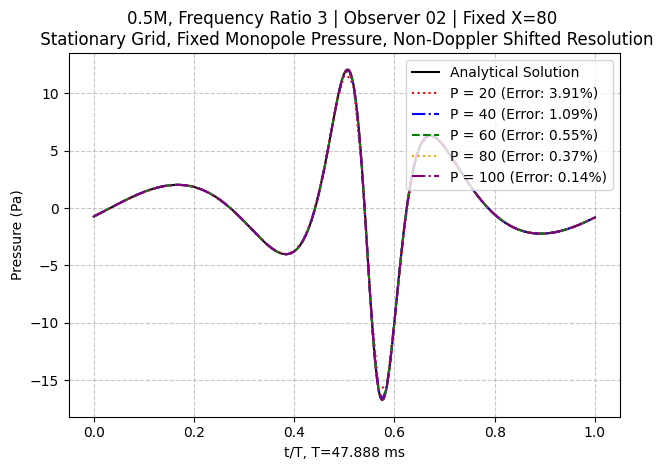

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


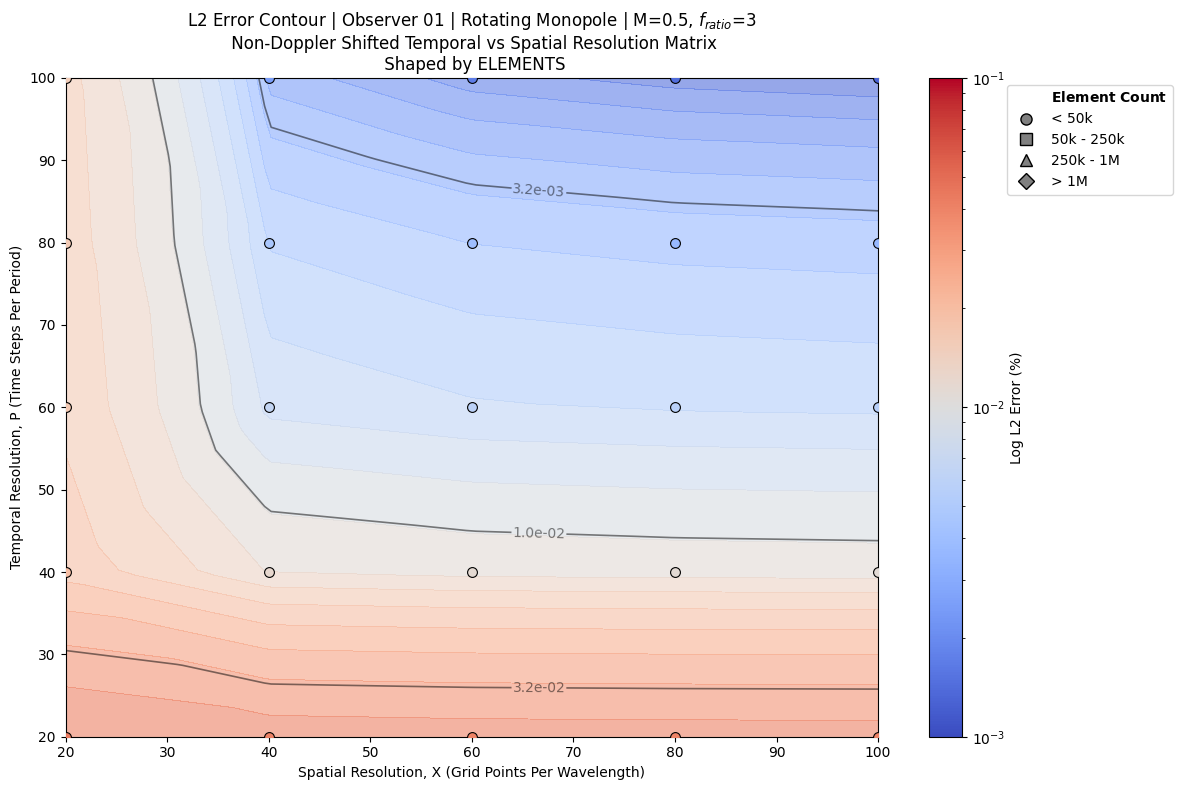

In [10]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio3_xpsweep')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 80
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 62.43
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=3', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


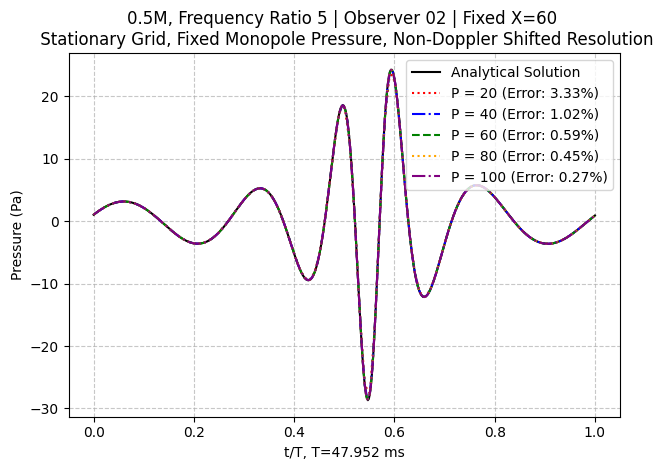

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


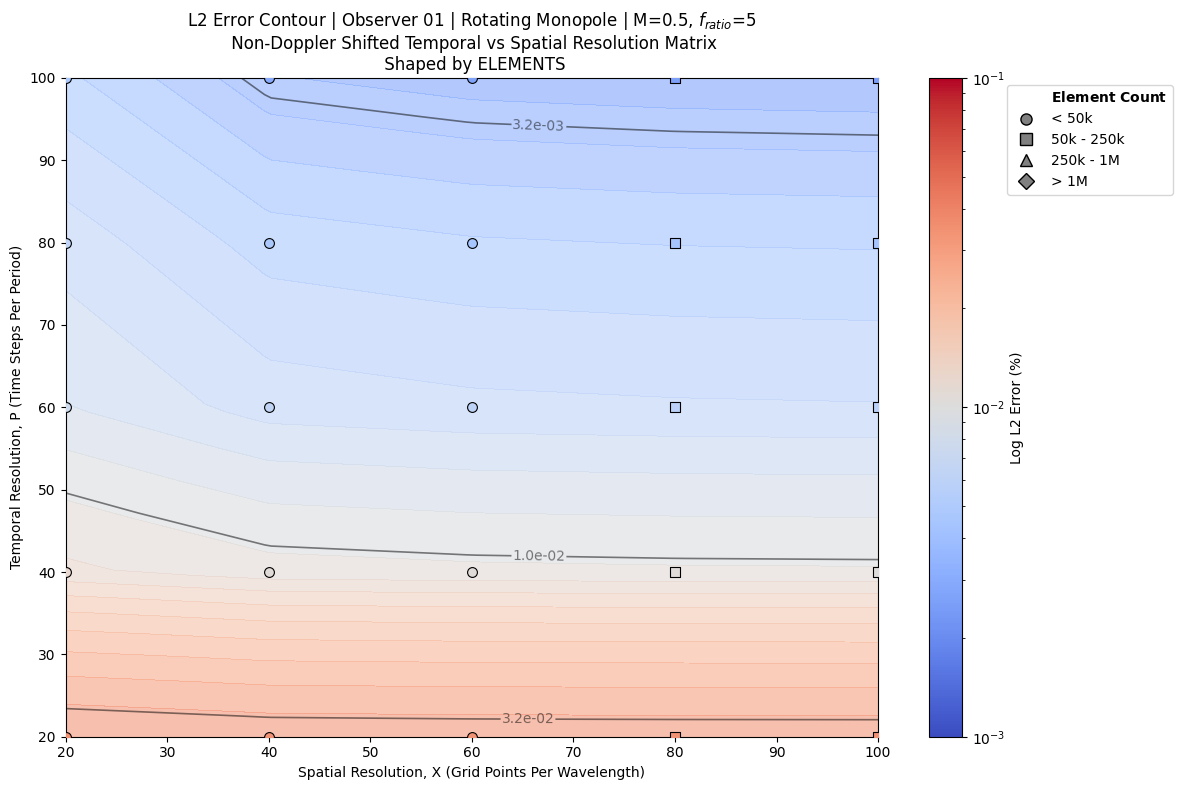

In [9]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio5_xpsweep')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 60
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.5M, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 104
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=5', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


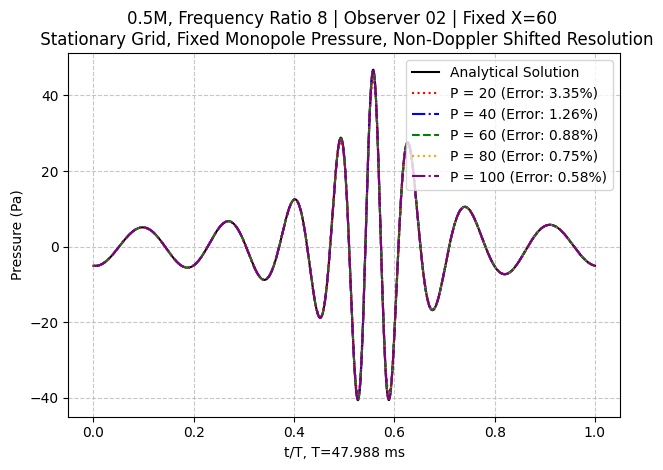

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


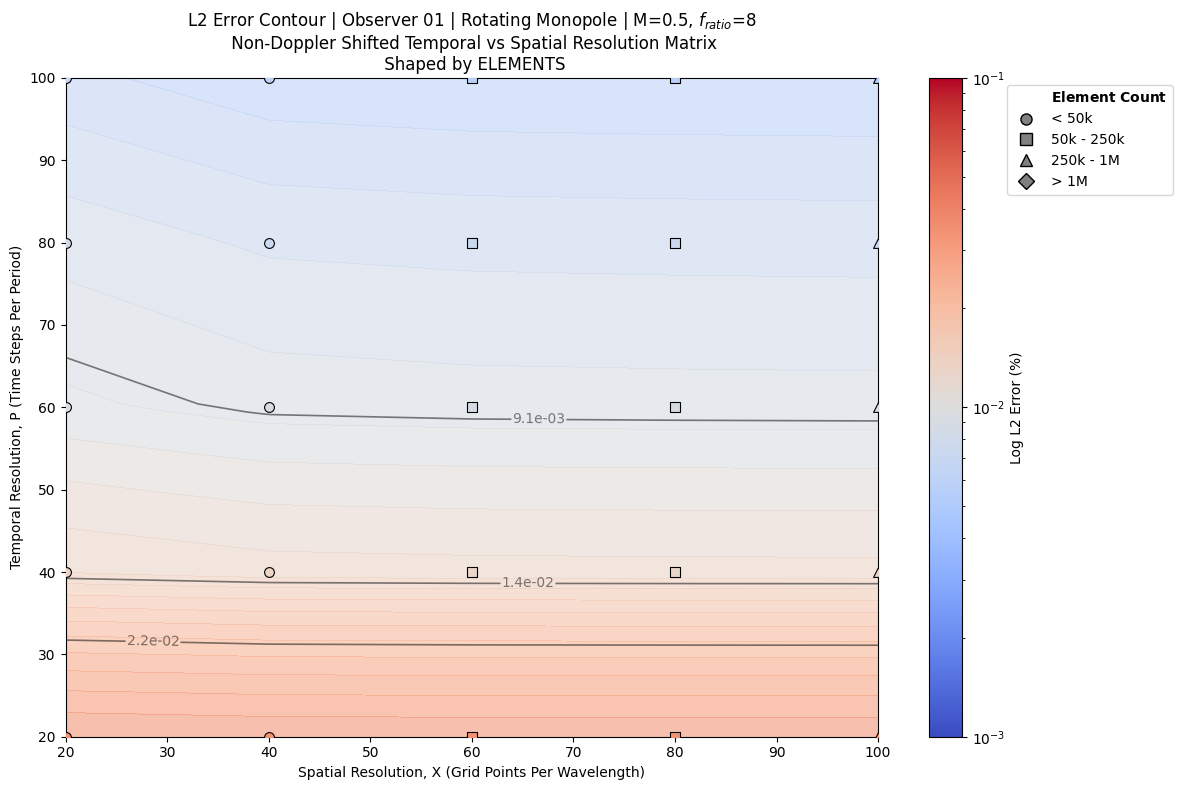

In [8]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio8_xpsweep')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 60
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.5M, Frequency Ratio 8 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 166.5
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=8', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


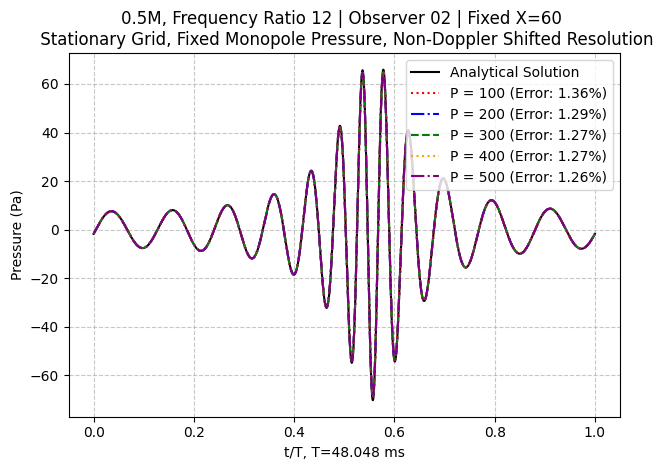

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


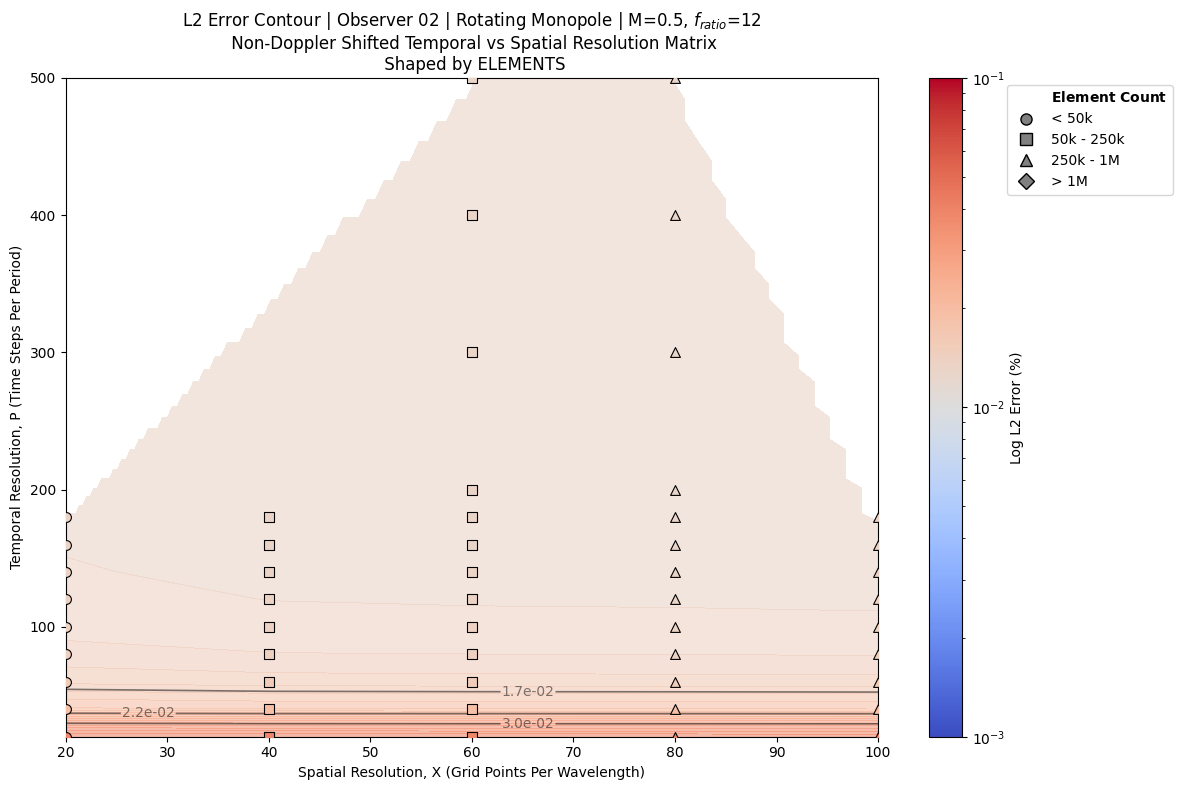

In [7]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep')
obs_id = ['02']   # Select target observer

x_fixed = 60
# p_test_vals = [20, 40, 60, 80, 100]
p_test_vals = [100, 200, 300, 400, 500]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.5M, Frequency Ratio 12 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 249.75
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['02']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=12', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


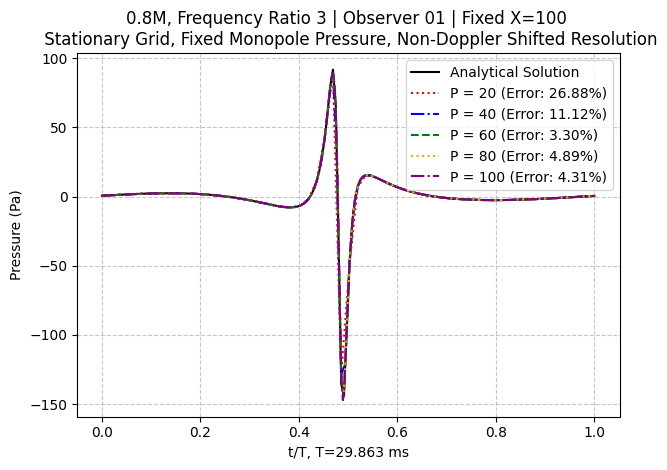

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


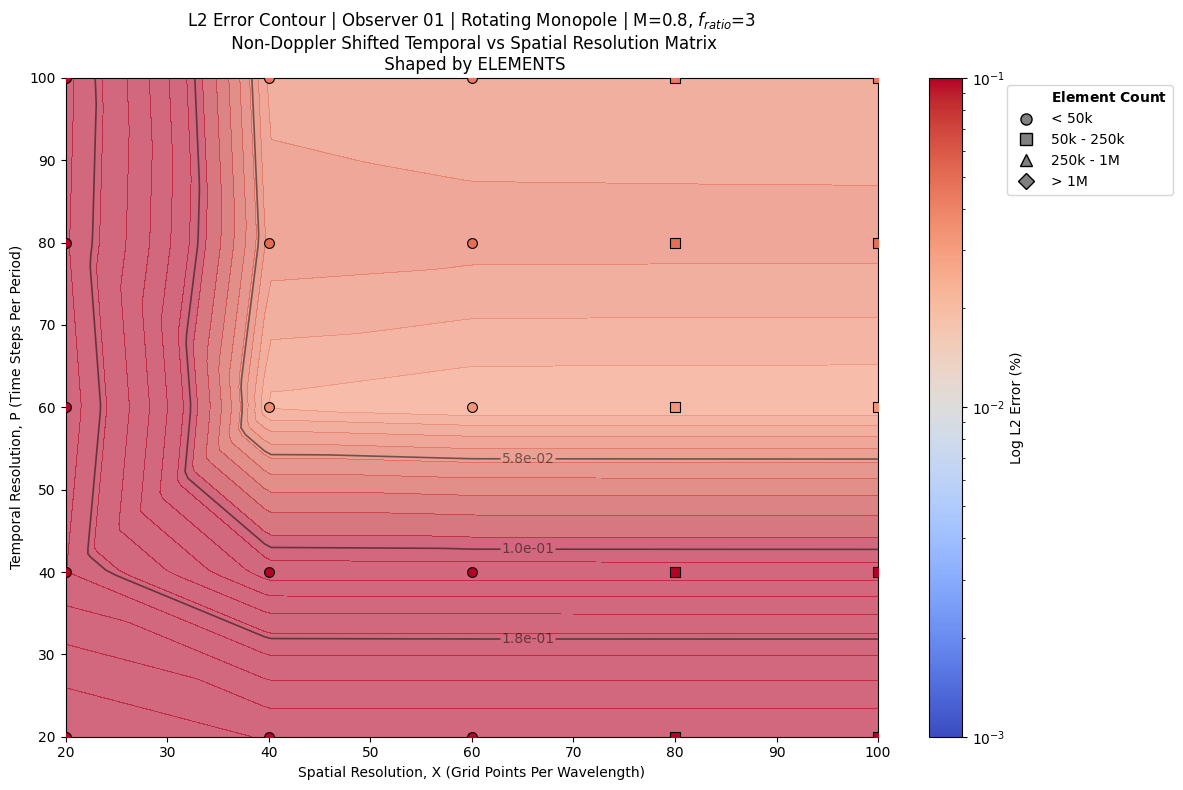

In [11]:
date = '260805'
filepath = Path(f'data_{date}/M0.8_fratio3_xpsweep')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.8M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 99.9
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=3', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


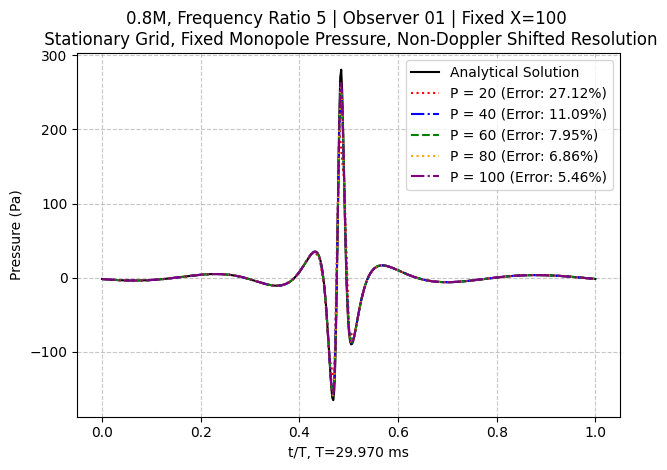

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


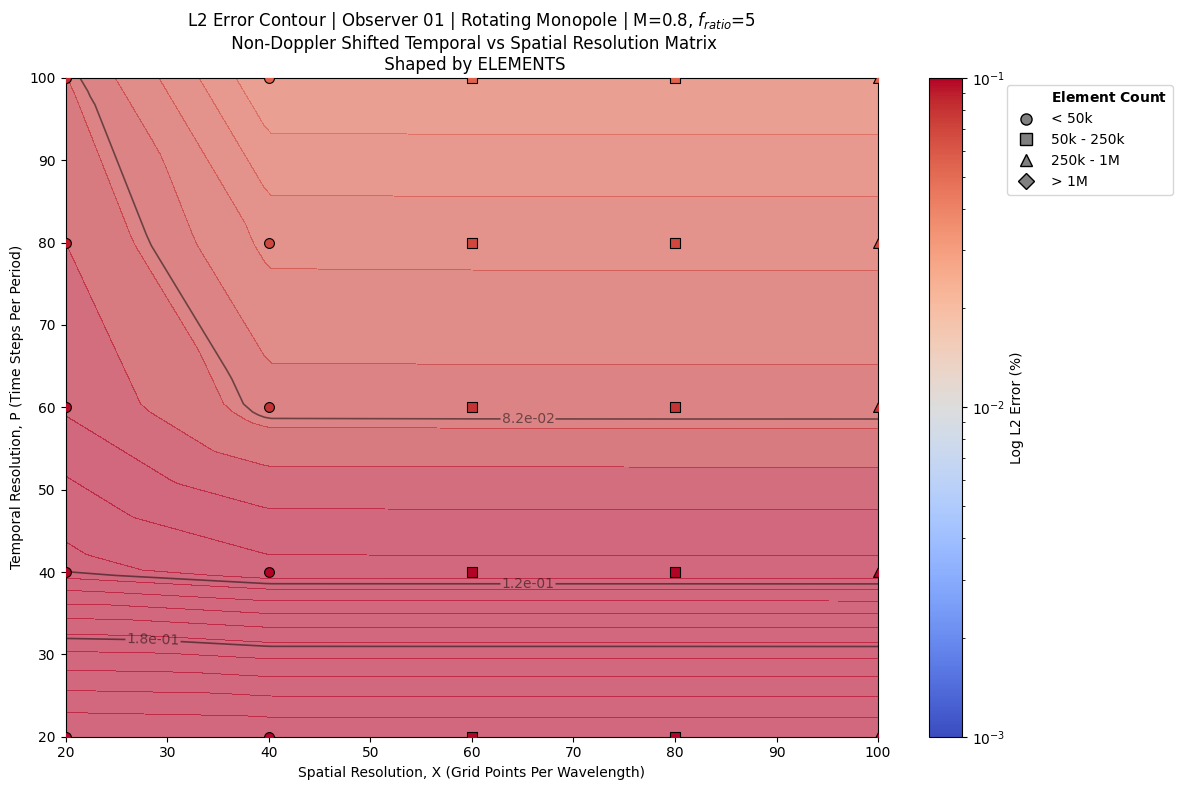

In [12]:
date = '260806'
filepath = Path(f'data_{date}/M0.8_fratio5')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.8M, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 166.5
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=5', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


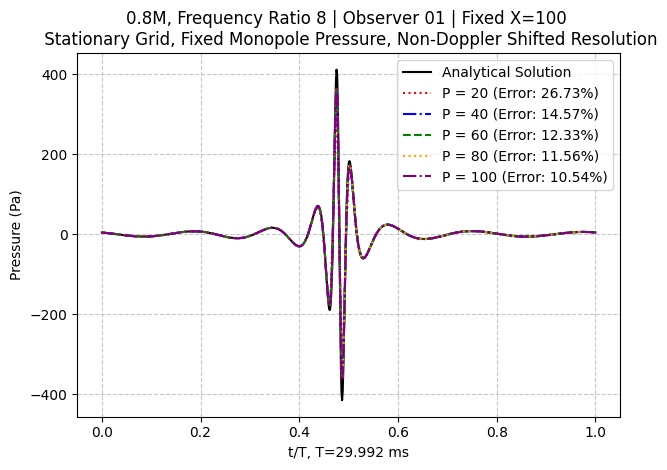

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


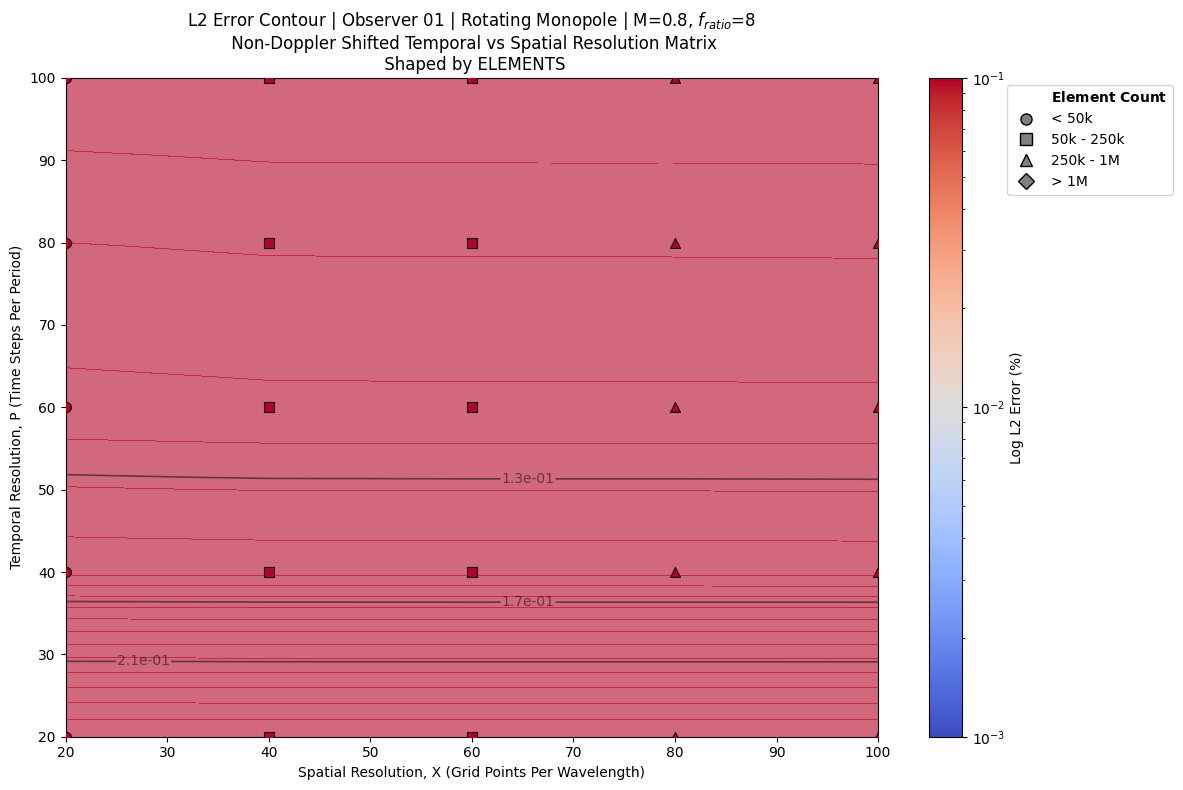

In [13]:
date = '260806'
filepath = Path(f'data_{date}/M0.8_fratio8')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.8M, Frequency Ratio 8 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 266.4
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=8', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 60
# p_test_vals = [20, 40, 60, 80, 100]

# for obs in obs_id:
#     # ana_path = filepath / f'ana_spatial_{obs}.dat'
#     # ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         # ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
#         error_method='l2',
#         x_axis='normalised'
#     )

# FWHDataset.R = 1.69         
# FWHDataset.C = 340.0
# FWHDataset.F_SOURCE = 99.9
# FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
# FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

# master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# # 2. Select observers to plot
# obs_target = ['01']

# for obs in obs_target:
#     # 3. Filter the master dataset for this specific observer
#     observer_data = [d for d in master_dataset if d['observer'] == obs]
    
#     if not observer_data:
#         print(f"No data found for Observer {obs}. Skipping.")
#         continue
        
#     # 4. Pass directly to the contour plotter
#     FWHPlotter.plot_px_contour_space(
#         observer_data, 
#         add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=5', 
#         use_doppler=False,
#         shape_by='elements',
#         draw_mach_lines=False,
#         vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
#         vmin=1e-3               
#     )


In [ ]:
date = '260728'
filepath = Path(f'data_{date}/M08_fratio12')
obs_id = ['01','02','03']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | Observer {obs} | Fixed X={x_fixed}',
        error_method='l2',
        # x_axis='normalised'
    )


In [ ]:
FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 400
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Multipole Validation', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


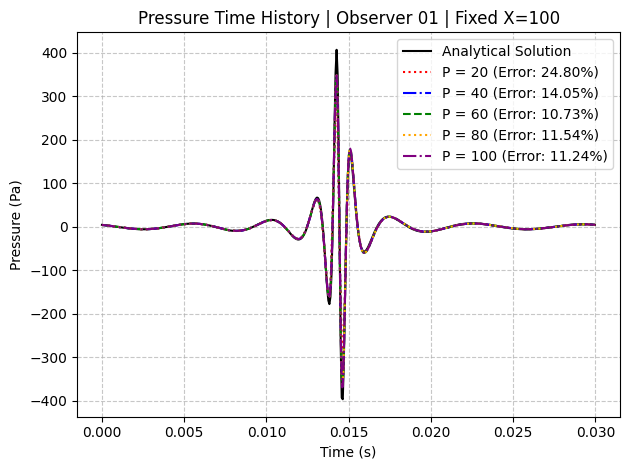

In [ ]:
# date = '260729'
# filepath = Path(f'data_{date}/M08_fratio8')
# obs_id = ['01']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 100
# p_test_vals = [20, 40, 60, 80, 100]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Pressure Time History | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         # x_axis='normalised'
#     )


In [ ]:
# FWHDataset.R = 1.69         
# FWHDataset.C = 340.0
# FWHDataset.F_SOURCE = 400 * 2 / 3
# FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
# FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

# master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# # 2. Select observers to plot
# obs_target = ['01']

# for obs in obs_target:
#     # 3. Filter the master dataset for this specific observer
#     observer_data = [d for d in master_dataset if d['observer'] == obs]
    
#     if not observer_data:
#         print(f"No data found for Observer {obs}. Skipping.")
#         continue
        
#     # 4. Pass directly to the contour plotter
#     FWHPlotter.plot_px_contour_space(
#         observer_data, 
#         add_title=f'L2 Error Contour | Observer {obs} | Multipole Validation', 
#         use_doppler=False,
#         shape_by='elements',
#         draw_mach_lines=False,
#         vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
#         vmin=1e-3               
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical_stationary_freestream')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Monopole Fix, Freestream X',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical_stationarygrid')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Monopole Fix, Doppler-shifted X',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical_doppler')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Rotating Grid, Monopole Fix, Doppler-shifted X',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260803'
# filepath = Path(f'data_{date}/M05_fratio3_dopplershifted')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Doppler-shifted Resolutions, Rotating Grid',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Rotating Grid, Monopole Fix',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260803'
# filepath = Path(f'data_{date}/M05_fratio3_rotatinggrid')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Rotating Grid',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260803'
# filepath = Path(f'data_{date}/M05_fratio3')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid',
#         error_method='l2',
#         x_axis='normalised'
#     )
